In [1]:
!pip install tensorflow scikit-learn matplotlib

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Dense,
    Flatten,
    Input,
    Dropout,
    Conv2D,
    MaxPooling2D,
    BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.19.0


In [4]:
(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

In [5]:
print('training images:',X_train.shape)
print('training labels:',y_train.shape)
print('test images:',X_test.shape)
print('test images:',X_test.shape)
print('test labels:',y_test.shape)

training images: (60000, 28, 28)
training labels: (60000,)
test images: (10000, 28, 28)
test images: (10000, 28, 28)
test labels: (10000,)


In [6]:
# Define class names
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]
for label, name in enumerate(class_names):
    print(label, "->", name)

0 -> T-shirt/top
1 -> Trouser
2 -> Pullover
3 -> Dress
4 -> Coat
5 -> Sandal
6 -> Shirt
7 -> Sneaker
8 -> Bag
9 -> Ankle boot


In [10]:
print(label)

9


In [11]:
print(name)

Ankle boot


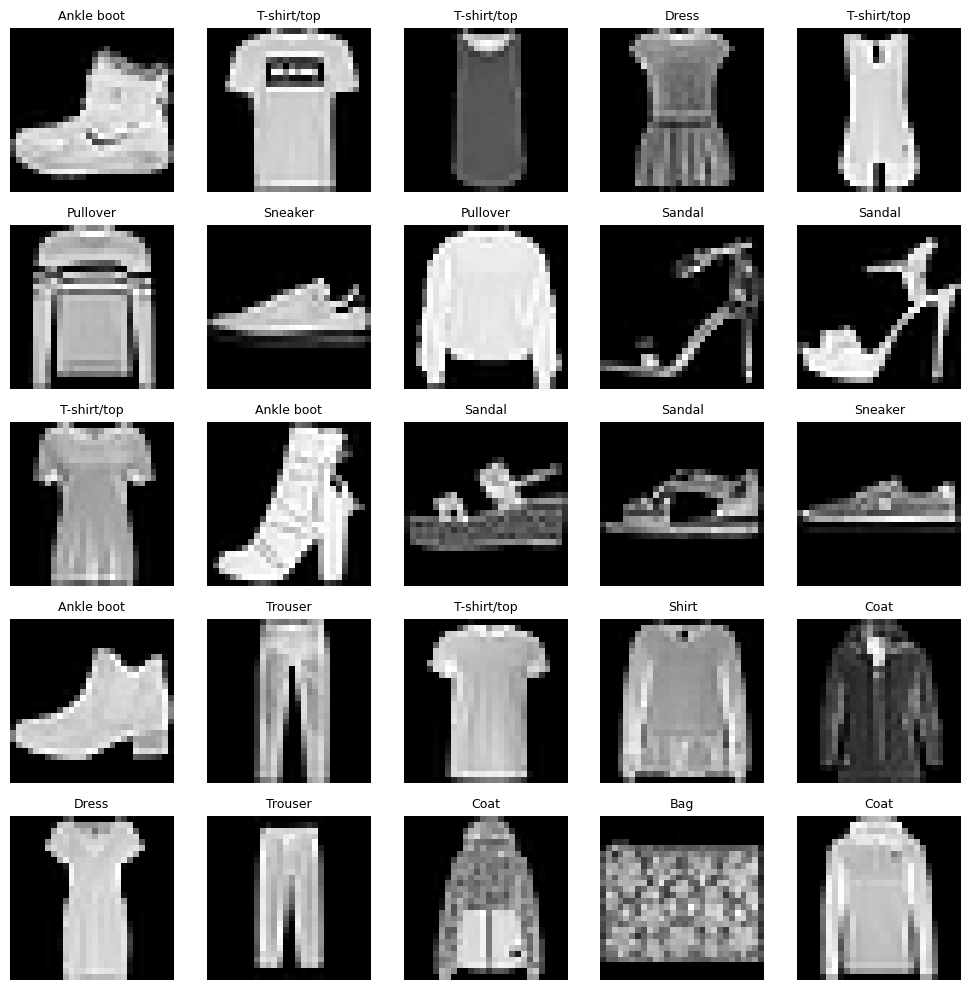

In [7]:
# View sample images
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
# Check pixel values
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())
print("Unique labels:", np.unique(y_train))
print("Class counts:")
print(np.bincount(y_train))

Minimum pixel value: 0
Maximum pixel value: 255
Unique labels: [0 1 2 3 4 5 6 7 8 9]
Class counts:
[6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


In [9]:
# Scale pixel values
X_train=X_train.astype('float32')/255.0
X_test=X_test.astype('float32')/255.0

print("New minimum:", X_train.min())
print("New maximum:", X_train.max())

New minimum: 0.0
New maximum: 1.0


In [10]:
dense_model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),

    Dense(256, activation="relu"),
    Dropout(0.3),

    Dense(128, activation="relu"),
    Dropout(0.2),

    Dense(10, activation="softmax")
])

dense_model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

dense_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

In [13]:
history_dense = dense_model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7851 - loss: 0.6007 - val_accuracy: 0.8498 - val_loss: 0.4142
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8409 - loss: 0.4340 - val_accuracy: 0.8601 - val_loss: 0.3800
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8564 - loss: 0.3961 - val_accuracy: 0.8673 - val_loss: 0.3631
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8648 - loss: 0.3690 - val_accuracy: 0.8778 - val_loss: 0.3394
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8700 - loss: 0.3527 - val_accuracy: 0.8781 - val_loss: 0.3340
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8737 - loss: 0.3427 - val_accuracy: 0.8788 - val_loss: 0.3267
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8769 - loss: 0.3310 - val_accuracy: 0.8816 - val_loss: 0.3216
Epoch 8/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8811 - loss: 0.3193 - val_accuracy: 0.

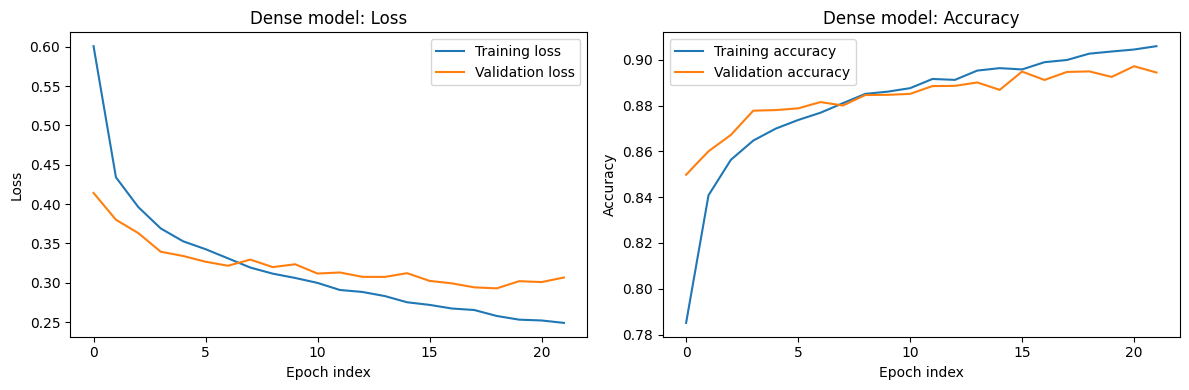

In [14]:
# Plot learning curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_dense.history["loss"], label="Training loss")
plt.plot(history_dense.history["val_loss"], label="Validation loss")
plt.title("Dense model: Loss")
plt.xlabel("Epoch index")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_dense.history["accuracy"], label="Training accuracy")
plt.plot(history_dense.history["val_accuracy"], label="Validation accuracy")
plt.title("Dense model: Accuracy")
plt.xlabel("Epoch index")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [15]:
# Evaluate on the test set
dense_test_loss, dense_test_accuracy = dense_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

y_prob_dense = dense_model.predict(X_test, verbose=0)
y_pred_dense = y_prob_dense.argmax(axis=1)

dense_macro_f1 = f1_score(
    y_test,
    y_pred_dense,
    average="macro"
)

print(f"Dense model test loss: {dense_test_loss:.4f}")
print(f"Dense model test accuracy: {dense_test_accuracy:.2%}")
print(f"Dense model macro-F1: {dense_macro_f1:.4f}")

Dense model test loss: 0.3232
Dense model test accuracy: 88.63%
Dense model macro-F1: 0.8852


<Figure size 1000x800 with 0 Axes>

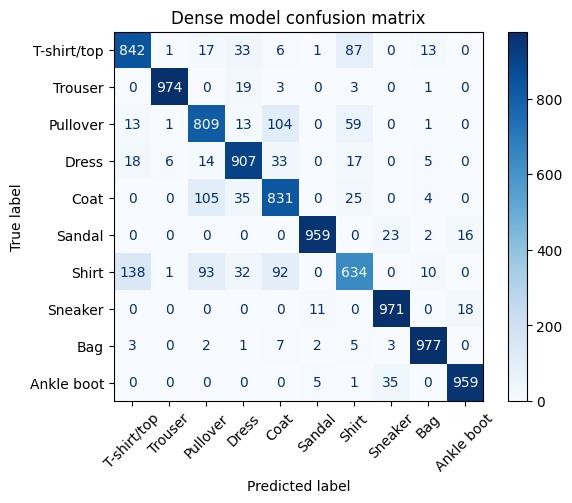

In [17]:
cm_dense = confusion_matrix(y_test, y_pred_dense)

plt.figure(figsize=(10, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm_dense,
    display_labels=class_names
).plot(
    values_format="d",
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Dense model confusion matrix")
plt.show()

Number of misclassified test images: 1137


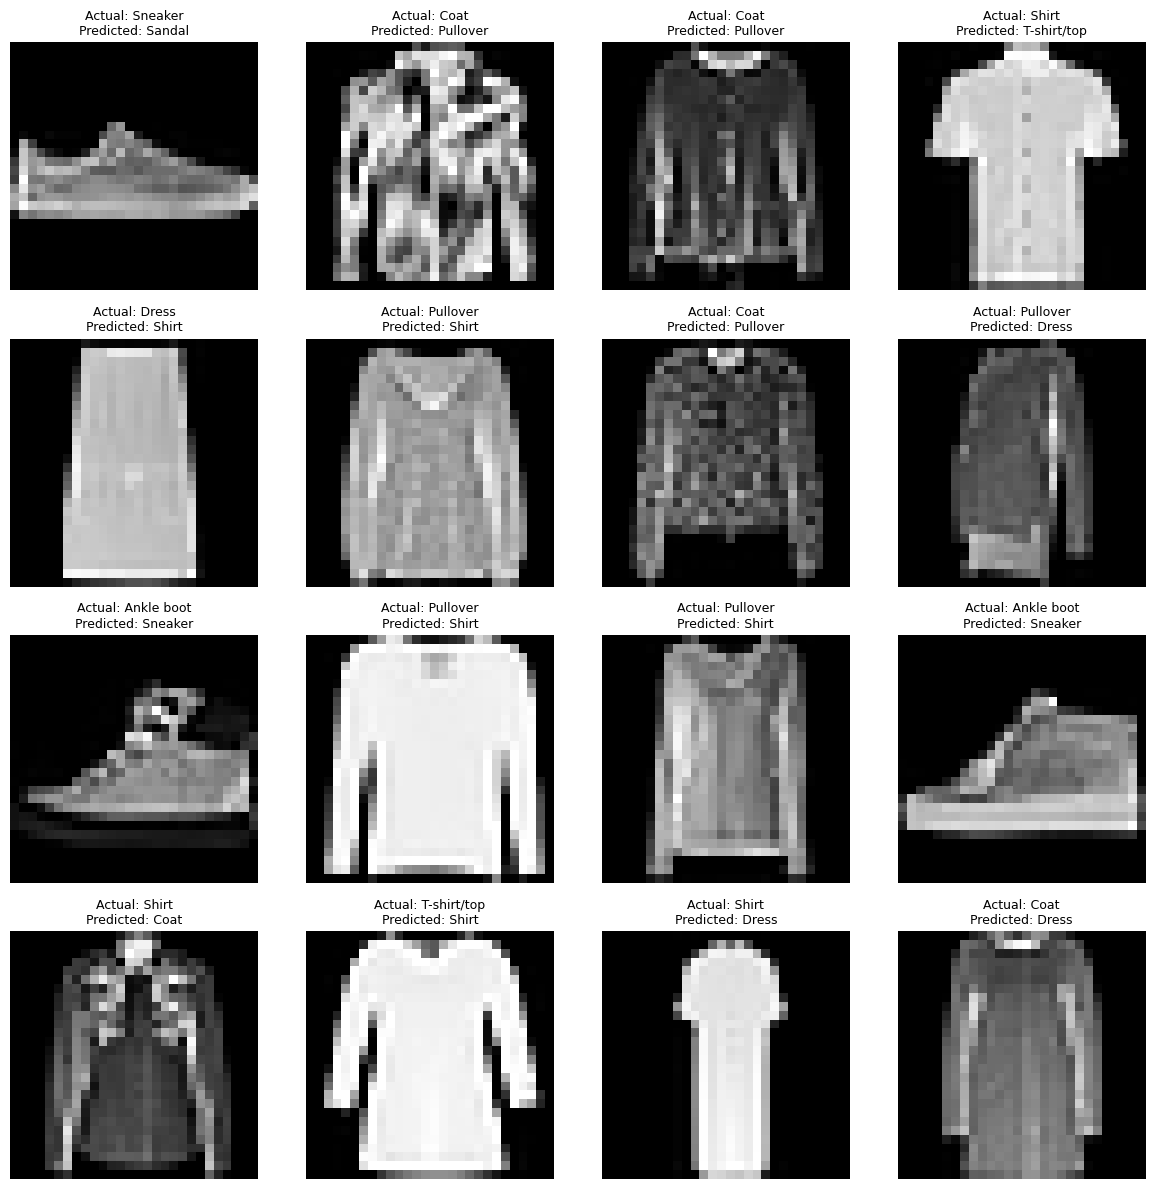

In [18]:
wrong_indices = np.where(y_pred_dense != y_test)[0]

print(f"Number of misclassified test images: {len(wrong_indices)}")

plt.figure(figsize=(12, 12))

for i, idx in enumerate(wrong_indices[:16]):
    plt.subplot(4, 4, i + 1)
    plt.imshow(X_test[idx], cmap="gray")
    plt.title(
        f"Actual: {class_names[y_test[idx]]}\n"
        f"Predicted: {class_names[y_pred_dense[idx]]}",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_val_cnn = X_val_cnn = X_train_cnn  # Not needed; see next cell

In [20]:
# Split validation data from training data
from sklearn.model_selection import train_test_split

X_train_cnn, X_val_cnn, y_train_cnn, y_val_cnn = train_test_split(
    X_train.reshape(-1, 28, 28, 1),
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

X_test_cnn = X_test.reshape(-1, 28, 28, 1)

print("CNN training shape:", X_train_cnn.shape)
print("CNN validation shape:", X_val_cnn.shape)
print("CNN test shape:", X_test_cnn.shape)

CNN training shape: (48000, 28, 28, 1)
CNN validation shape: (12000, 28, 28, 1)
CNN test shape: (10000, 28, 28, 1)


In [22]:
cnn_model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, kernel_size=(3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    Conv2D(32, kernel_size=(3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Conv2D(64, kernel_size=(3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    Conv2D(64, kernel_size=(3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.4),

    Dense(10, activation="softmax")
])

cnn_model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)                    │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 28, 28, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 28, 28, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 28, 28, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_6                │ (None, 14, 14, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 14, 14, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_7                │ (None, 14, 14, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 3136)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 128)                 │         401,536 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 468,586 (1.79 MB)

 Trainable params: 468,202 (1.79 MB)

 Non-trainable params: 384 (1.50 KB)

In [23]:
history_cnn = cnn_model.fit(
    X_train_cnn,
    y_train_cnn,
    validation_data=(X_val_cnn, y_val_cnn),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 60s 79ms/step - accuracy: 0.8009 - loss: 0.5629 - val_accuracy: 0.8861 - val_loss: 0.3046
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 53s 71ms/step - accuracy: 0.8706 - loss: 0.3665 - val_accuracy: 0.8959 - val_loss: 0.2753
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 55s 73ms/step - accuracy: 0.8885 - loss: 0.3132 - val_accuracy: 0.9127 - val_loss: 0.2480
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 60s 80ms/step - accuracy: 0.8974 - loss: 0.2857 - val_accuracy: 0.9047 - val_loss: 0.2628
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 61s 81ms/step - accuracy: 0.9031 - loss: 0.2683 - val_accuracy: 0.9231 - val_loss: 0.2179
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 61s 82ms/step - accuracy: 0.9122 - loss: 0.2439 - val_accuracy: 0.9162 - val_loss: 0.2377
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 60s 81ms/step - accuracy: 0.9161 - loss: 0.2306 - val_accuracy: 0.9156 - val_loss: 0.2357
Epoch 8/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 64s 85ms/step - accuracy: 0.9184 - loss: 0.2215 - 

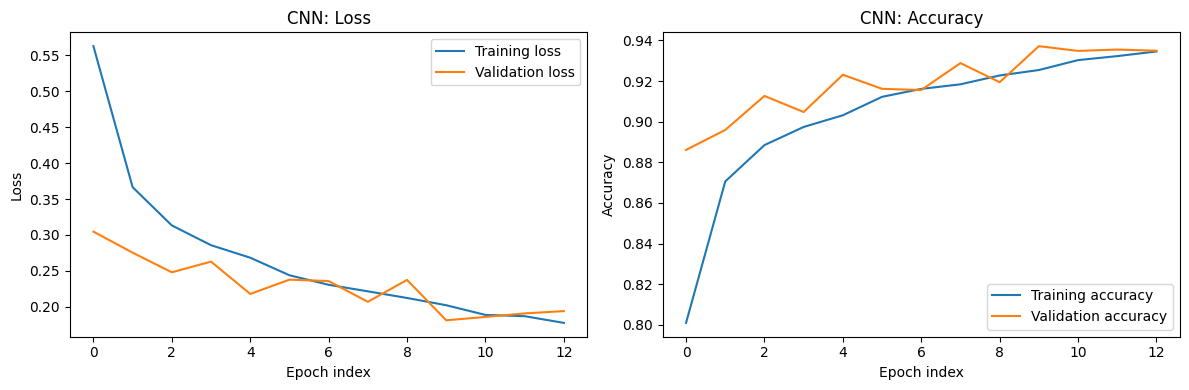

In [24]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["loss"], label="Training loss")
plt.plot(history_cnn.history["val_loss"], label="Validation loss")
plt.title("CNN: Loss")
plt.xlabel("Epoch index")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["accuracy"], label="Training accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation accuracy")
plt.title("CNN: Accuracy")
plt.xlabel("Epoch index")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [25]:
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

y_prob_cnn = cnn_model.predict(X_test_cnn, verbose=0)
y_pred_cnn = y_prob_cnn.argmax(axis=1)

cnn_macro_f1 = f1_score(
    y_test,
    y_pred_cnn,
    average="macro"
)

print(f"CNN test loss: {cnn_test_loss:.4f}")
print(f"CNN test accuracy: {cnn_test_accuracy:.2%}")
print(f"CNN macro-F1: {cnn_macro_f1:.4f}")

CNN test loss: 0.2070
CNN test accuracy: 92.67%
CNN macro-F1: 0.9264


In [26]:
print(classification_report(
    y_test,
    y_pred_cnn,
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

 T-shirt/top     0.8485    0.8960    0.8716      1000
     Trouser     0.9959    0.9810    0.9884      1000
    Pullover     0.9062    0.8980    0.9021      1000
       Dress     0.9047    0.9400    0.9220      1000
        Coat     0.8957    0.8930    0.8943      1000
      Sandal     0.9939    0.9810    0.9874      1000
       Shirt     0.8036    0.7490    0.7754      1000
     Sneaker     0.9464    0.9890    0.9672      1000
         Bag     0.9890    0.9880    0.9885      1000
  Ankle boot     0.9825    0.9520    0.9670      1000

    accuracy                         0.9267     10000
   macro avg     0.9266    0.9267    0.9264     10000
weighted avg     0.9266    0.9267    0.9264     10000



<Figure size 1000x800 with 0 Axes>

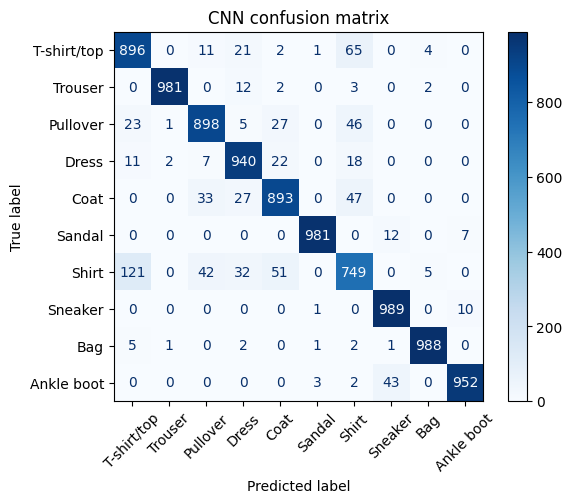

In [27]:
cm_cnn = confusion_matrix(y_test, y_pred_cnn)

plt.figure(figsize=(10, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=class_names
).plot(
    values_format="d",
    cmap="Blues",
    xticks_rotation=45
)

plt.title("CNN confusion matrix")
plt.show()

In [28]:
results = {
    "Dense model": {
        "Test accuracy": dense_test_accuracy,
        "Macro-F1": dense_macro_f1
    },
    "CNN model": {
        "Test accuracy": cnn_test_accuracy,
        "Macro-F1": cnn_macro_f1
    }
}

results_df = pd.DataFrame(results).T

results_df

,Test accuracy,Macro-F1
Dense model,0.8863,0.885238
CNN model,0.9267,0.926393


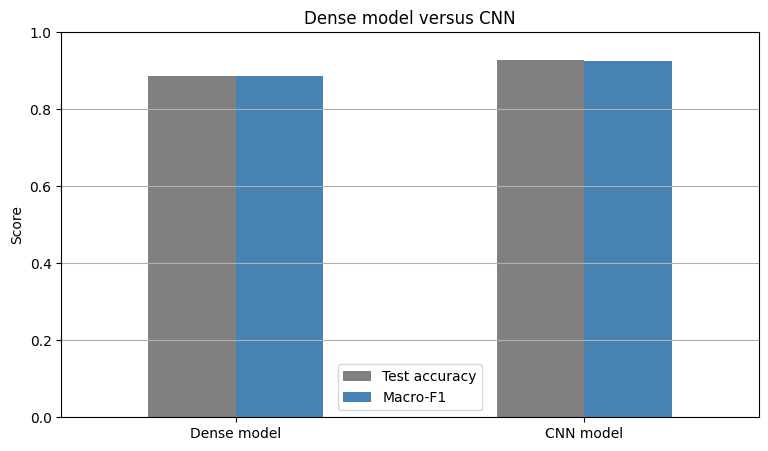

In [29]:
results_df.plot(
    kind="bar",
    figsize=(9, 5),
    color=["gray", "steelblue"]
)

plt.title("Dense model versus CNN")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.grid(axis="y")
plt.show()

In [30]:
if cnn_test_accuracy > dense_test_accuracy:
    best_model = cnn_model
    best_model_name = "CNN model"
else:
    best_model = dense_model
    best_model_name = "Dense model"

best_model.save("fashion_mnist_best_model.keras")

print(f"Best model: {best_model_name}")
print("Model saved successfully.")

Best model: CNN model
Model saved successfully.


In [33]:
loaded_model = keras.models.load_model("fashion_mnist_best_model.keras")

image_index = 4

# Use CNN input if the CNN was selected
single_image = X_test_cnn[image_index:image_index + 1]

probabilities = loaded_model.predict(single_image, verbose=0)[0]
predicted_label = probabilities.argmax()

print("Predicted class:", class_names[predicted_label])
print("Actual class:", class_names[y_test[image_index]])

print("\nClass probabilities:")
for class_name, probability in zip(class_names, probabilities):
    print(f"{class_name}: {probability:.4f}")

Predicted class: Shirt
Actual class: Shirt

Class probabilities:
T-shirt/top: 0.1020
Trouser: 0.0000
Pullover: 0.0060
Dress: 0.0023
Coat: 0.0006
Sandal: 0.0000
Shirt: 0.8892
Sneaker: 0.0000
Bag: 0.0000
Ankle boot: 0.0000


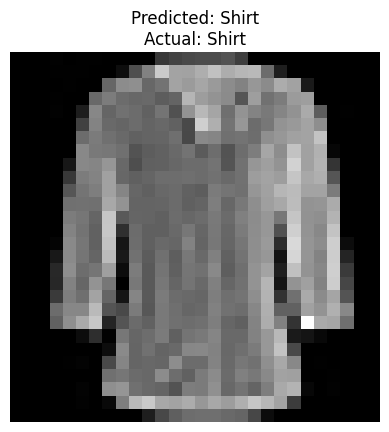

In [34]:
plt.figure()
plt.imshow(X_test[image_index], cmap="gray")
plt.title(
    f"Predicted: {class_names[predicted_label]}\n"
    f"Actual: {class_names[y_test[image_index]]}"
)
plt.axis("off")
plt.show()